<a href="https://colab.research.google.com/github/ayoitshasya/respiratory-disorder-detection/blob/main/multi_res_and_handcrafted.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os, zipfile

DATA_ROOT = '/content/drive/MyDrive/pulmoscan semester 7'
ZIP_PATH  = os.path.join(DATA_ROOT, 'pulmoscan_raw_audio.zip')
EXTRACT_TO = '/content/pulmoscan_raw'

os.makedirs(EXTRACT_TO, exist_ok=True)
with zipfile.ZipFile(ZIP_PATH, 'r') as zf:
    zf.extractall(EXTRACT_TO)

MANIFEST_PATH = os.path.join(EXTRACT_TO, 'processed', 'manifest.csv')
CYCLES_DIR    = os.path.join(EXTRACT_TO, 'cycles', 'processed_training_cycles')
print('Manifest exists:', os.path.exists(MANIFEST_PATH))
print('Cycle wavs found:', len(os.listdir(CYCLES_DIR)))

Mounted at /content/drive
Manifest exists: True
Cycle wavs found: 5319


In [ ]:
import numpy as np
import pandas as pd
import tensorflow as tf
import librosa
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.signal import butter, filtfilt
from sklearn.metrics import confusion_matrix, classification_report, recall_score
from tqdm import tqdm

print('TF version:', tf.__version__)
print('GPU:', tf.config.list_physical_devices('GPU'))

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

TF version: 2.20.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
SR           = 16000
MIN_DURATION = 2.0
MAX_DURATION = 8.0
LOW_CUT      = 100
HIGH_CUT     = 2000
FILTER_ORDER = 4
N_FFT        = 2048
N_MELS       = 128
FMIN         = 50
FMAX         = 2000
TARGET_FRAMES = 63

NUM_SOUND     = 4
NUM_DIAGNOSIS = 7
BATCH_SIZE    = 32
EPOCHS        = 80
LR            = 1e-3
LR_MIN        = 1e-6
DIAG_WEIGHT   = 0.1

SOUND_NAMES   = ['Normal', 'Crackle', 'Wheeze', 'Both']
CLASS_WEIGHTS = [0.44, 1.15, 1.72, 3.56]

CKPT_DIR    = '/content/checkpoints'
RESULTS_DIR = '/content/results'
import os
os.makedirs(CKPT_DIR, exist_ok=True)
os.makedirs(RESULTS_DIR, exist_ok=True)

CKPT_NAME = 'multitask_dualres_best.keras'

BASELINE_ICBHI_SCORE = 0.6226
BASELINE_RECALL = {'Normal': 0.49, 'Crackle': 0.59, 'Wheeze': 0.42, 'Both': 0.24}

In [ ]:
manifest = pd.read_csv(MANIFEST_PATH)
manifest['audio_path'] = manifest['audio_file'].apply(
    lambda f: os.path.join(CYCLES_DIR, f)
)

train_df = manifest[manifest['split'] == 'train'].reset_index(drop=True)
val_df   = manifest[manifest['split'] == 'val'].reset_index(drop=True)
print(f'Train: {len(train_df)} | Val: {len(val_df)}')
print(train_df['sound_label'].value_counts().sort_index())

assert os.path.exists(train_df.iloc[0]['audio_path']), 'audio_path remap failed'

Train: 2891 | Val: 799
sound_label
0    1643
1     626
2     419
3     203
Name: count, dtype: int64


In [ ]:
def butterworth_filter(audio, lowcut=LOW_CUT, highcut=HIGH_CUT, fs=SR, order=FILTER_ORDER):
    nyq  = 0.5 * fs
    low  = lowcut / nyq
    high = highcut / nyq
    b, a = butter(order, [low, high], btype='band')
    return filtfilt(b, a, audio)


def normalise_duration(audio, sr=SR, min_dur=MIN_DURATION, max_dur=MAX_DURATION):
    min_len = int(min_dur * sr)
    max_len = int(max_dur * sr)
    if len(audio) < min_len:
        audio = np.pad(audio, (0, min_len - len(audio)))
    elif len(audio) > max_len:
        audio = audio[:max_len]
    return audio


def load_and_prep_audio(path):
    audio, _ = librosa.load(path, sr=SR, mono=True)
    audio = butterworth_filter(audio)
    audio = normalise_duration(audio)
    return audio


def icbhi_score(y_true, y_pred, n=NUM_SOUND):
    cm = confusion_matrix(y_true, y_pred, labels=list(range(n)))
    se, sp = [], []
    for i in range(n):
        tp = cm[i, i]
        fn = cm[i, :].sum() - tp
        fp = cm[:, i].sum() - tp
        tn = cm.sum() - tp - fn - fp
        se.append(tp / (tp + fn) if tp + fn > 0 else 0.0)
        sp.append(tn / (tn + fp) if tn + fp > 0 else 0.0)
    return (np.mean(se) + np.mean(sp)) / 2.0


def pad_or_truncate(feat, t=TARGET_FRAMES):
    c = feat.shape[-1]
    if c < t:
        feat = np.pad(feat, [(0, 0), (0, t - c)])
    else:
        feat = feat[..., :t]
    return feat

In [ ]:
FILTERED_DIR = '/content/filtered_audio'
os.makedirs(FILTERED_DIR, exist_ok=True)

def cache_filtered(df):
    paths = []
    for _, row in tqdm(df.iterrows(), total=len(df), desc='Filtering'):
        out_path = os.path.join(FILTERED_DIR, os.path.basename(row['audio_path']) + '.npy')
        if not os.path.exists(out_path):
            audio = load_and_prep_audio(row['audio_path'])
            np.save(out_path, audio)
        paths.append(out_path)
    return paths

train_df['filtered_path'] = cache_filtered(train_df)
val_df['filtered_path']   = cache_filtered(val_df)
print('Cached filtered audio for', len(train_df) + len(val_df), 'files')

Filtering: 100%|██████████| 799/799 [00:04<00:00, 197.04it/s]

Cached filtered audio for 3690 files


In [ ]:
def mel_spec(audio, hop_length):
    mel = librosa.feature.melspectrogram(
        y=audio, sr=SR, n_fft=N_FFT, hop_length=hop_length,
        n_mels=N_MELS, fmin=FMIN, fmax=FMAX, power=2.0
    )
    mel_db = librosa.power_to_db(mel, ref=np.max)
    mel_db = (mel_db - mel_db.mean()) / (mel_db.std() + 1e-8)
    return mel_db.astype(np.float32)


def dual_res_feature(filtered_path):
    audio = np.load(filtered_path)
    fine   = pad_or_truncate(mel_spec(audio, hop_length=256))
    coarse = pad_or_truncate(mel_spec(audio, hop_length=512))
    return np.stack([fine, coarse], axis=-1)


def load_split_A(df):
    X, ys, yd = [], [], []
    for _, row in tqdm(df.iterrows(), total=len(df), desc='Building dual-res features'):
        X.append(dual_res_feature(row['filtered_path']))
        ys.append(row['sound_label'])
        yd.append(row['diagnosis_label'])
    return np.array(X, np.float32), np.array(ys, np.int32), np.array(yd, np.int32)


print('Building val features...')
X_val_A, y_sv_A, y_dv_A = load_split_A(val_df)
print(f'Val: {X_val_A.shape}')

print('Building train features...')
X_tr_A, y_str_A, y_dtr_A = load_split_A(train_df)
print(f'Train: {X_tr_A.shape}')

y_str_A_oh = tf.keras.utils.to_categorical(y_str_A, NUM_SOUND)
y_dtr_A_oh = tf.keras.utils.to_categorical(y_dtr_A, NUM_DIAGNOSIS)
y_sv_A_oh  = tf.keras.utils.to_categorical(y_sv_A,  NUM_SOUND)
y_dv_A_oh  = tf.keras.utils.to_categorical(y_dv_A,  NUM_DIAGNOSIS)

Building val features...


Building dual-res features: 100%|██████████| 799/799 [00:31<00:00, 25.01it/s]


Val: (799, 128, 63, 2)
Building train features...


Building dual-res features: 100%|██████████| 2891/2891 [01:04<00:00, 44.92it/s]


Train: (2891, 128, 63, 2)


In [ ]:
def focal_loss(gamma=2.0, class_weights=None):
    def loss_fn(y_true, y_pred):
        y_pred = tf.clip_by_value(y_pred, 1e-7, 1.0)
        ce = -y_true * tf.math.log(y_pred)
        p_t = tf.reduce_sum(y_true * y_pred, axis=-1, keepdims=True)
        focal = tf.pow(1.0 - p_t, gamma) * ce
        if class_weights is not None:
            weights = tf.reduce_sum(
                y_true * tf.constant(class_weights, dtype=tf.float32),
                axis=-1, keepdims=True
            )
            focal = focal * weights
        return tf.reduce_mean(focal)
    loss_fn.__name__ = 'focal_loss'
    return loss_fn


def build_model_A():
    inp = tf.keras.Input(shape=(N_MELS, TARGET_FRAMES, 2))

    x = tf.keras.layers.Conv2D(32, 3, padding='same', activation='relu')(inp)
    x = tf.keras.layers.BatchNormalization()(x)
    x = tf.keras.layers.MaxPooling2D(2)(x)

    x = tf.keras.layers.Conv2D(64, 3, padding='same', activation='relu')(x)
    x = tf.keras.layers.BatchNormalization()(x)
    x = tf.keras.layers.MaxPooling2D(2)(x)

    x = tf.keras.layers.Conv2D(128, 3, padding='same', activation='relu')(x)
    x = tf.keras.layers.BatchNormalization()(x)
    x = tf.keras.layers.MaxPooling2D(2)(x)

    x = tf.keras.layers.Conv2D(256, 3, padding='same', activation='relu')(x)
    x = tf.keras.layers.BatchNormalization()(x)
    x = tf.keras.layers.GlobalAveragePooling2D()(x)

    shared = tf.keras.layers.Dense(256, activation='relu')(x)
    shared = tf.keras.layers.Dropout(0.5)(shared)

    s = tf.keras.layers.Dense(128, activation='relu')(shared)
    s = tf.keras.layers.Dropout(0.3)(s)
    sound_out = tf.keras.layers.Dense(NUM_SOUND, activation='softmax', name='sound')(s)

    d = tf.keras.layers.Dense(128, activation='relu')(shared)
    d = tf.keras.layers.Dropout(0.3)(d)
    diag_out = tf.keras.layers.Dense(NUM_DIAGNOSIS, activation='softmax', name='diagnosis')(d)

    return tf.keras.Model(inp, [sound_out, diag_out])


model_A = build_model_A()
model_A.summary()
print(f'\nTotal params: {model_A.count_params():,}')

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 128, 63,   │          0 │ -                 │
│ (InputLayer)        │ 2)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 128, 63,   │        608 │ input_layer[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 128, 63,   │        128 │ conv2d[0][0]      │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 64, 31,    │          0 │ batch_normalizat… │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 64, 31,    │     18,496 │ max_pooling2d[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64, 31,    │        256 │ conv2d_1[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_1     │ (None, 32, 15,    │          0 │ batch_normalizat… │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 32, 15,    │     73,856 │ max_pooling2d_1[… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 32, 15,    │        512 │ conv2d_2[0][0]    │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_2     │ (None, 16, 7,     │          0 │ batch_normalizat… │
│ (MaxPooling2D)      │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 16, 7,     │    295,168 │ max_pooling2d_2[… │
│                     │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 16, 7,     │      1,024 │ conv2d_3[0][0]    │
│ (BatchNormalizatio… │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 256)       │          0 │ batch_normalizat… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 256)       │     65,792 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 256)       │          0 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 128)       │     32,896 │ dropout[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 128)       │     32,896 │ dropout[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 128)       │          0 │ dense_1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼─────────────────

 Total params: 523,051 (2.00 MB)

 Trainable params: 522,091 (1.99 MB)

 Non-trainable params: 960 (3.75 KB)


Total params: 523,051


In [ ]:
class ICBHICallback(tf.keras.callbacks.Callback):
    def __init__(self, X, y, ckpt_path):
        super().__init__()
        self.X = X
        self.y = y
        self.ckpt_path = ckpt_path
        self.best = 0.0

    def on_epoch_end(self, epoch, logs=None):
        pred = np.argmax(self.model.predict(self.X, verbose=0)[0], axis=1)
        score = icbhi_score(self.y, pred)
        logs['val_icbhi'] = score
        if score > self.best:
            self.best = score
            self.model.save(self.ckpt_path)
            print(f'  val_icbhi: {score:.4f} *** NEW BEST -- saved ***')
        else:
            print(f'  val_icbhi: {score:.4f}')


def lr_schedule(epoch):
    cos = np.cos(np.pi * epoch / EPOCHS)
    return float(LR_MIN + 0.5 * (LR - LR_MIN) * (1 + cos))


CKPT_A = os.path.join(CKPT_DIR, CKPT_NAME)

callbacks_A = [
    ICBHICallback(X_val_A, y_sv_A, CKPT_A),
    tf.keras.callbacks.EarlyStopping(
        monitor='val_icbhi', mode='max',
        patience=20, restore_best_weights=True, verbose=1),
    tf.keras.callbacks.LearningRateScheduler(lr_schedule, verbose=0),
]

model_A.compile(
    optimizer=tf.keras.optimizers.Adam(LR),
    loss={'sound': focal_loss(4.0, CLASS_WEIGHTS), 'diagnosis': focal_loss(2.0)},
    loss_weights={'sound': 1.0, 'diagnosis': DIAG_WEIGHT},
    metrics={'sound': 'accuracy', 'diagnosis': 'accuracy'}
)

print('Model compiled.')

Model compiled.


In [ ]:
print('Starting Experiment A training...')
history_A = model_A.fit(
    X_tr_A, {'sound': y_str_A_oh, 'diagnosis': y_dtr_A_oh},
    validation_data=(X_val_A, {'sound': y_sv_A_oh, 'diagnosis': y_dv_A_oh}),
    batch_size=BATCH_SIZE,
    epochs=EPOCHS,
    callbacks=callbacks_A,
    verbose=1
)

best_icbhi_A = max(history_A.history['val_icbhi'])
print(f'\nBest val_icbhi (Experiment A): {best_icbhi_A:.4f}')

Starting Experiment A training...
Epoch 1/80
91/91 ━━━━━━━━━━━━━━━━━━━━ 0s 97ms/step - diagnosis_accuracy: 0.7757 - diagnosis_loss: 0.0938 - loss: 0.1268 - sound_accuracy: 0.3484 - sound_loss: 0.1174  val_icbhi: 0.5151 *** NEW BEST -- saved ***
91/91 ━━━━━━━━━━━━━━━━━━━━ 31s 146ms/step - diagnosis_accuracy: 0.8011 - diagnosis_loss: 0.0799 - loss: 0.1195 - sound_accuracy: 0.3528 - sound_loss: 0.1113 - val_diagnosis_accuracy: 0.7347 - val_diagnosis_loss: 0.1054 - val_loss: 0.1157 - val_sound_accuracy: 0.5194 - val_sound_loss: 0.1050 - val_icbhi: 0.5151 - learning_rate: 0.0010
Epoch 2/80
89/91 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - diagnosis_accuracy: 0.8149 - diagnosis_loss: 0.0652 - loss: 0.0977 - sound_accuracy: 0.4158 - sound_loss: 0.0912  val_icbhi: 0.5288 *** NEW BEST -- saved ***
91/91 ━━━━━━━━━━━━━━━━━━━━ 2s 20ms/step - diagnosis_accuracy: 0.8101 - diagnosis_loss: 0.0652 - loss: 0.1010 - sound_accuracy: 0.3909 - sound_loss: 0.0943 - val_diagnosis_accuracy: 0.7322 - val_diagnosis_loss

In [ ]:
model_A_best = tf.keras.models.load_model(CKPT_A, compile=False)
val_preds_A  = model_A_best.predict(X_val_A, batch_size=128)
y_pred_A     = np.argmax(val_preds_A[0], axis=1)

from sklearn.metrics import confusion_matrix, recall_score, classification_report

icbhi_A  = icbhi_score(y_sv_A, y_pred_A)
recall_A = recall_score(y_sv_A, y_pred_A, labels=list(range(NUM_SOUND)), average=None, zero_division=0)
cm_A     = confusion_matrix(y_sv_A, y_pred_A, labels=list(range(NUM_SOUND)))

print('=== EXPERIMENT A: Multi-resolution spectrogram ===')
print(f'ICBHI score: {icbhi_A:.4f} ({icbhi_A*100:.2f}%)')
print('\nPer-class recall:')
for name, r in zip(SOUND_NAMES, recall_A):
    print(f'  {name:10s}: {r:.4f} ({r*100:.1f}%)')
print('\nConfusion matrix (rows=true, cols=pred):')
print(cm_A)
print('\n=== vs baseline ===')
print(f'ICBHI: {BASELINE_ICBHI_SCORE*100:.2f}% -> {icbhi_A*100:.2f}% ({(icbhi_A-BASELINE_ICBHI_SCORE)*100:+.2f}pt)')
for name, r in zip(SOUND_NAMES, recall_A):
    b = BASELINE_RECALL[name]
    print(f'{name:10s}: {b*100:.1f}% -> {r*100:.1f}%  ({(r-b)*100:+.1f}pt)')

7/7 ━━━━━━━━━━━━━━━━━━━━ 5s 236ms/step
=== EXPERIMENT A: Multi-resolution spectrogram ===
ICBHI score: 0.6030 (60.30%)

Per-class recall:
  Normal    : 0.4269 (42.7%)
  Crackle   : 0.3382 (33.8%)
  Wheeze    : 0.5833 (58.3%)
  Both      : 0.3103 (31.0%)

Confusion matrix (rows=true, cols=pred):
[[216 102 164  24]
 [ 56  69  75   4]
 [ 16   4  35   5]
 [  8   3   9   9]]

=== vs baseline ===
ICBHI: 62.26% -> 60.30% (-1.96pt)
Normal    : 49.0% -> 42.7%  (-6.3pt)
Crackle   : 59.0% -> 33.8%  (-25.2pt)
Wheeze    : 42.0% -> 58.3%  (+16.3pt)
Both      : 24.0% -> 31.0%  (+7.0pt)


In [ ]:
def build_model_baseline():
    inp = tf.keras.Input(shape=(N_MELS, TARGET_FRAMES, 1))

    x = tf.keras.layers.Conv2D(32, 3, padding='same', activation='relu')(inp)
    x = tf.keras.layers.BatchNormalization()(x)
    x = tf.keras.layers.MaxPooling2D(2)(x)
    x = tf.keras.layers.Conv2D(64, 3, padding='same', activation='relu')(x)
    x = tf.keras.layers.BatchNormalization()(x)
    x = tf.keras.layers.MaxPooling2D(2)(x)
    x = tf.keras.layers.Conv2D(128, 3, padding='same', activation='relu')(x)
    x = tf.keras.layers.BatchNormalization()(x)
    x = tf.keras.layers.MaxPooling2D(2)(x)
    x = tf.keras.layers.Conv2D(256, 3, padding='same', activation='relu')(x)
    x = tf.keras.layers.BatchNormalization()(x)
    x = tf.keras.layers.GlobalAveragePooling2D()(x)

    shared = tf.keras.layers.Dense(256, activation='relu')(x)
    shared = tf.keras.layers.Dropout(0.5)(shared)

    s = tf.keras.layers.Dense(128, activation='relu')(shared)
    s = tf.keras.layers.Dropout(0.3)(s)
    sound_out = tf.keras.layers.Dense(NUM_SOUND, activation='softmax', name='sound')(s)

    d = tf.keras.layers.Dense(128, activation='relu')(shared)
    d = tf.keras.layers.Dropout(0.3)(d)
    diag_out = tf.keras.layers.Dense(NUM_DIAGNOSIS, activation='softmax', name='diagnosis')(d)

    return tf.keras.Model(inp, [sound_out, diag_out])


# Load single channel features from cached filtered audio
def load_split_baseline(df):
    X, ys, yd = [], [], []
    for _, row in tqdm(df.iterrows(), total=len(df), desc='Loading baseline features'):
        audio = np.load(row['filtered_path'])
        mel = librosa.feature.melspectrogram(
            y=audio, sr=SR, n_fft=N_FFT, hop_length=256,
            n_mels=N_MELS, fmin=FMIN, fmax=FMAX, power=2.0
        )
        mel_db = librosa.power_to_db(mel, ref=np.max)
        mel_db = (mel_db - mel_db.mean()) / (mel_db.std() + 1e-8)
        feat = pad_or_truncate(mel_db.astype(np.float32))
        feat = feat[..., np.newaxis]
        X.append(feat)
        ys.append(row['sound_label'])
        yd.append(row['diagnosis_label'])
    return np.array(X, np.float32), np.array(ys, np.int32), np.array(yd, np.int32)

print('Loading baseline val features...')
X_val_B, y_sv_B, y_dv_B = load_split_baseline(val_df)
print(f'Val: {X_val_B.shape}')

print('Loading baseline train features...')
X_tr_B, y_str_B, y_dtr_B = load_split_baseline(train_df)
print(f'Train: {X_tr_B.shape}')

y_str_B_oh = tf.keras.utils.to_categorical(y_str_B, NUM_SOUND)
y_dtr_B_oh = tf.keras.utils.to_categorical(y_dtr_B, NUM_DIAGNOSIS)
y_sv_B_oh  = tf.keras.utils.to_categorical(y_sv_B,  NUM_SOUND)
y_dv_B_oh  = tf.keras.utils.to_categorical(y_dv_B,  NUM_DIAGNOSIS)

Loading baseline val features...


Loading baseline features: 100%|██████████| 799/799 [00:25<00:00, 31.74it/s]


Val: (799, 128, 63, 1)
Loading baseline train features...


Loading baseline features: 100%|██████████| 2891/2891 [00:41<00:00, 69.12it/s]

Train: (2891, 128, 63, 1)


In [ ]:
model_B = build_model_baseline()

CKPT_B = os.path.join(CKPT_DIR, 'multitask_baseline_best.keras')

callbacks_B = [
    ICBHICallback(X_val_B, y_sv_B, CKPT_B),
    tf.keras.callbacks.EarlyStopping(
        monitor='val_icbhi', mode='max',
        patience=20, restore_best_weights=True, verbose=1),
    tf.keras.callbacks.LearningRateScheduler(lr_schedule, verbose=0),
]

model_B.compile(
    optimizer=tf.keras.optimizers.Adam(LR),
    loss={'sound': focal_loss(4.0, CLASS_WEIGHTS), 'diagnosis': focal_loss(2.0)},
    loss_weights={'sound': 1.0, 'diagnosis': DIAG_WEIGHT},
    metrics={'sound': 'accuracy', 'diagnosis': 'accuracy'}
)

print('Starting baseline training...')
history_B = model_B.fit(
    X_tr_B, {'sound': y_str_B_oh, 'diagnosis': y_dtr_B_oh},
    validation_data=(X_val_B, {'sound': y_sv_B_oh, 'diagnosis': y_dv_B_oh}),
    batch_size=BATCH_SIZE,
    epochs=EPOCHS,
    callbacks=callbacks_B,
    verbose=1
)

best_icbhi_B = max(history_B.history['val_icbhi'])
print(f'\nBest val_icbhi (baseline retrain): {best_icbhi_B:.4f}')

Starting baseline training...
Epoch 1/80
91/91 ━━━━━━━━━━━━━━━━━━━━ 0s 100ms/step - diagnosis_accuracy: 0.7454 - diagnosis_loss: 0.0990 - loss: 0.1280 - sound_accuracy: 0.3460 - sound_loss: 0.1181  val_icbhi: 0.5307 *** NEW BEST -- saved ***
91/91 ━━━━━━━━━━━━━━━━━━━━ 31s 142ms/step - diagnosis_accuracy: 0.7980 - diagnosis_loss: 0.0836 - loss: 0.1185 - sound_accuracy: 0.3580 - sound_loss: 0.1102 - val_diagnosis_accuracy: 0.7347 - val_diagnosis_loss: 0.1119 - val_loss: 0.1444 - val_sound_accuracy: 0.5056 - val_sound_loss: 0.1331 - val_icbhi: 0.5307 - learning_rate: 0.0010
Epoch 2/80
90/91 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - diagnosis_accuracy: 0.8148 - diagnosis_loss: 0.0703 - loss: 0.1000 - sound_accuracy: 0.3955 - sound_loss: 0.0930  val_icbhi: 0.4990
91/91 ━━━━━━━━━━━━━━━━━━━━ 2s 18ms/step - diagnosis_accuracy: 0.8122 - diagnosis_loss: 0.0698 - loss: 0.1027 - sound_accuracy: 0.3784 - sound_loss: 0.0956 - val_diagnosis_accuracy: 0.7347 - val_diagnosis_loss: 0.1185 - val_loss: 0.1545 -

In [ ]:
# Get softmax probabilities from both models
model_A_best = tf.keras.models.load_model(CKPT_A, compile=False)
model_B_best = tf.keras.models.load_model(CKPT_B, compile=False)

probs_A = model_A_best.predict(X_val_A, batch_size=128)[0]  # multi-res
probs_B = model_B_best.predict(X_val_B, batch_size=128)[0]  # baseline

# Make sure labels match
assert np.array_equal(y_sv_A, y_sv_B), 'Label mismatch between splits'
y_true = y_sv_A

# Simple average ensemble
probs_avg = (probs_A + probs_B) / 2.0
y_pred_avg = np.argmax(probs_avg, axis=1)
icbhi_avg = icbhi_score(y_true, y_pred_avg)
recall_avg = recall_score(y_true, y_pred_avg, labels=list(range(NUM_SOUND)), average=None, zero_division=0)

print('=== ENSEMBLE (simple average) ===')
print(f'ICBHI: {icbhi_avg*100:.2f}%')
for name, r in zip(SOUND_NAMES, recall_avg):
    print(f'  {name:10s}: {r*100:.1f}%')

# Weighted search — try different weights for each model
print('\nSearching best ensemble weights...')
best_score = 0
best_w = 0.5
for w in np.arange(0.1, 1.0, 0.05):
    probs_w = w * probs_A + (1-w) * probs_B
    score = icbhi_score(y_true, np.argmax(probs_w, axis=1))
    if score > best_score:
        best_score = score
        best_w = w

print(f'\nBest weight for multi-res: {best_w:.2f}, baseline: {1-best_w:.2f}')
probs_best = best_w * probs_A + (1-best_w) * probs_B
y_pred_best = np.argmax(probs_best, axis=1)
recall_best = recall_score(y_true, y_pred_best, labels=list(range(NUM_SOUND)), average=None, zero_division=0)

print(f'\n=== BEST WEIGHTED ENSEMBLE ===')
print(f'ICBHI: {best_score*100:.2f}%')
for name, r in zip(SOUND_NAMES, recall_best):
    b = BASELINE_RECALL[name]
    print(f'  {name:10s}: {b*100:.1f}% -> {r*100:.1f}%  ({(r-b)*100:+.1f}pt)')

print(f'\nBaseline alone:   {BASELINE_ICBHI_SCORE*100:.2f}%')
print(f'Multi-res alone:  60.30%')
print(f'Ensemble:         {best_score*100:.2f}%')

7/7 ━━━━━━━━━━━━━━━━━━━━ 4s 257ms/step
7/7 ━━━━━━━━━━━━━━━━━━━━ 2s 157ms/step
=== ENSEMBLE (simple average) ===
ICBHI: 62.28%
  Normal    : 63.2%
  Crackle   : 27.5%
  Wheeze    : 56.7%
  Both      : 24.1%

Searching best ensemble weights...

Best weight for multi-res: 0.35, baseline: 0.65

=== BEST WEIGHTED ENSEMBLE ===
ICBHI: 63.67%
  Normal    : 49.0% -> 66.4%  (+17.4pt)
  Crackle   : 59.0% -> 25.5%  (-33.5pt)
  Wheeze    : 42.0% -> 51.7%  (+9.7pt)
  Both      : 24.0% -> 37.9%  (+13.9pt)

Baseline alone:   62.26%
Multi-res alone:  60.30%
Ensemble:         63.67%


In [ ]:
print('Threshold tuning on best weighted ensemble probabilities...')
probs_ensemble = best_w * probs_A + (1-best_w) * probs_B

best_score_t = 0
best_tw = None

for n_w in np.arange(0.4, 1.2, 0.1):
    for c_w in np.arange(1.0, 3.0, 0.2):
        for w_w in np.arange(0.4, 2.0, 0.2):
            for b_w in np.arange(0.5, 3.0, 0.2):
                tw = np.array([n_w, c_w, w_w, b_w])
                preds = np.argmax(probs_ensemble * tw, axis=1)
                score = icbhi_score(y_true, preds)
                if score > best_score_t:
                    best_score_t = score
                    best_tw = tw.copy()

print(f'Best threshold weights: {best_tw}')
y_pred_t = np.argmax(probs_ensemble * best_tw, axis=1)
recall_t = recall_score(y_true, y_pred_t, labels=list(range(NUM_SOUND)), average=None, zero_division=0)

print(f'\n=== ENSEMBLE + THRESHOLD TUNING ===')
print(f'ICBHI: {best_score_t*100:.2f}%')
for name, r, b in zip(SOUND_NAMES, recall_t, BASELINE_RECALL.values()):
    print(f'  {name:10s}: {b*100:.1f}% -> {r*100:.1f}%  ({(r-b)*100:+.1f}pt)')

print(f'\nBaseline alone:            {BASELINE_ICBHI_SCORE*100:.2f}%')
print(f'Ensemble no tuning:        {best_score*100:.2f}%')
print(f'Ensemble + threshold:      {best_score_t*100:.2f}%')

Threshold tuning on best weighted ensemble probabilities...
Best threshold weights: [1.  1.  0.6 1.3]

=== ENSEMBLE + THRESHOLD TUNING ===
ICBHI: 64.95%
  Normal    : 49.0% -> 81.0%  (+32.0pt)
  Crackle   : 59.0% -> 34.8%  (-24.2pt)
  Wheeze    : 42.0% -> 6.7%  (-35.3pt)
  Both      : 24.0% -> 65.5%  (+41.5pt)

Baseline alone:            62.26%
Ensemble no tuning:        63.67%
Ensemble + threshold:      64.95%


In [ ]:
print('Constrained threshold search (min 30% recall per class)...')

best_score_c = 0
best_tw_c = None
MIN_RECALL = 0.30

for n_w in np.arange(0.4, 1.5, 0.1):
    for c_w in np.arange(0.8, 2.5, 0.2):
        for w_w in np.arange(0.8, 2.5, 0.2):
            for b_w in np.arange(0.8, 3.0, 0.2):
                tw = np.array([n_w, c_w, w_w, b_w])
                preds = np.argmax(probs_ensemble * tw, axis=1)
                recalls = recall_score(y_true, preds, labels=list(range(NUM_SOUND)), average=None, zero_division=0)
                if recalls.min() < MIN_RECALL:
                    continue
                score = icbhi_score(y_true, preds)
                if score > best_score_c:
                    best_score_c = score
                    best_tw_c = tw.copy()

if best_tw_c is None:
    print('No combination found with min 30% recall on all classes. Trying 25%...')
    MIN_RECALL = 0.25
    for n_w in np.arange(0.4, 1.5, 0.1):
        for c_w in np.arange(0.8, 2.5, 0.2):
            for w_w in np.arange(0.8, 2.5, 0.2):
                for b_w in np.arange(0.8, 3.0, 0.2):
                    tw = np.array([n_w, c_w, w_w, b_w])
                    preds = np.argmax(probs_ensemble * tw, axis=1)
                    recalls = recall_score(y_true, preds, labels=list(range(NUM_SOUND)), average=None, zero_division=0)
                    if recalls.min() < MIN_RECALL:
                        continue
                    score = icbhi_score(y_true, preds)
                    if score > best_score_c:
                        best_score_c = score
                        best_tw_c = tw.copy()

print(f'Best constrained weights: {best_tw_c}')
y_pred_c = np.argmax(probs_ensemble * best_tw_c, axis=1)
recall_c = recall_score(y_true, y_pred_c, labels=list(range(NUM_SOUND)), average=None, zero_division=0)

print(f'\n=== ENSEMBLE + CONSTRAINED THRESHOLD ===')
print(f'ICBHI: {best_score_c*100:.2f}%')
for name, r, b in zip(SOUND_NAMES, recall_c, BASELINE_RECALL.values()):
    print(f'  {name:10s}: {b*100:.1f}% -> {r*100:.1f}%  ({(r-b)*100:+.1f}pt)')

print(f'\nBaseline alone:            {BASELINE_ICBHI_SCORE*100:.2f}%')
print(f'Ensemble unconstrained:    {best_score_t*100:.2f}%')
print(f'Ensemble constrained:      {best_score_c*100:.2f}%')

Constrained threshold search (min 30% recall per class)...
Best constrained weights: [1.3 1.4 1.  1.2]

=== ENSEMBLE + CONSTRAINED THRESHOLD ===
ICBHI: 63.83%
  Normal    : 49.0% -> 70.4%  (+21.4pt)
  Crackle   : 59.0% -> 44.6%  (-14.4pt)
  Wheeze    : 42.0% -> 33.3%  (-8.7pt)
  Both      : 24.0% -> 31.0%  (+7.0pt)

Baseline alone:            62.26%
Ensemble unconstrained:    64.95%
Ensemble constrained:      63.83%


In [ ]:
import json

results = {
    'baseline_retrain_icbhi': float(best_icbhi_B),
    'multires_icbhi': 0.6030,
    'ensemble_simple_icbhi': float(icbhi_avg),
    'ensemble_weighted_icbhi': float(best_score),
    'ensemble_constrained_icbhi': float(best_score_c),
    'ensemble_weights_model': {'multires': float(best_w), 'baseline': float(1-best_w)},
    'ensemble_threshold_weights': best_tw_c.tolist(),
    'per_class_recall': {
        name: float(r) for name, r in zip(SOUND_NAMES, recall_c)
    }
}

save_path = '/content/drive/MyDrive/pulmoscan semester 7/ensemble_results.json'
with open(save_path, 'w') as f:
    json.dump(results, f, indent=2)
print('Saved to Drive.')
print(json.dumps(results, indent=2))

Saved to Drive.
{
  "baseline_retrain_icbhi": 0.6114462508297891,
  "multires_icbhi": 0.603,
  "ensemble_simple_icbhi": 0.6227567022060589,
  "ensemble_weighted_icbhi": 0.6367461853910301,
  "ensemble_constrained_icbhi": 0.6383139029248439,
  "ensemble_weights_model": {
    "multires": 0.3500000000000001,
    "baseline": 0.6499999999999999
  },
  "ensemble_threshold_weights": [
    1.2999999999999998,
    1.4,
    1.0,
    1.2
  ],
  "per_class_recall": {
    "Normal": 0.7035573122529645,
    "Crackle": 0.44607843137254904,
    "Wheeze": 0.3333333333333333,
    "Both": 0.3103448275862069
  }
}


In [ ]:
import json

results = {
    'baseline_retrain_icbhi': float(best_icbhi_B),
    'multires_icbhi': 0.6030,
    'ensemble_simple_icbhi': float(icbhi_avg),
    'ensemble_weighted_icbhi': float(best_score),
    'ensemble_constrained_icbhi': float(best_score_c),
    'ensemble_weights_model': {'multires': float(best_w), 'baseline': float(1-best_w)},
    'ensemble_threshold_weights': best_tw_c.tolist(),
    'per_class_recall': {
        name: float(r) for name, r in zip(SOUND_NAMES, recall_c)
    }
}

save_path = '/content/drive/MyDrive/pulmoscan semester 7/ensemble_results.json'
with open(save_path, 'w') as f:
    json.dump(results, f, indent=2)
print('Saved to Drive.')
print(json.dumps(results, indent=2))

Saved to Drive.
{
  "baseline_retrain_icbhi": 0.6114462508297891,
  "multires_icbhi": 0.603,
  "ensemble_simple_icbhi": 0.6227567022060589,
  "ensemble_weighted_icbhi": 0.6367461853910301,
  "ensemble_constrained_icbhi": 0.6383139029248439,
  "ensemble_weights_model": {
    "multires": 0.3500000000000001,
    "baseline": 0.6499999999999999
  },
  "ensemble_threshold_weights": [
    1.2999999999999998,
    1.4,
    1.0,
    1.2
  ],
  "per_class_recall": {
    "Normal": 0.7035573122529645,
    "Crackle": 0.44607843137254904,
    "Wheeze": 0.3333333333333333,
    "Both": 0.3103448275862069
  }
}


In [ ]:
# Stage 1: Binary Normal vs Abnormal
# Use the single channel baseline features (already in memory as X_tr_B, X_val_B)

# Binary labels: 0 = Normal, 1 = Abnormal (Crackle, Wheeze, Both)
y_tr_binary  = (y_str_B != 0).astype(np.int32)
y_val_binary = (y_sv_B  != 0).astype(np.int32)

print('Stage 1 binary distribution:')
print(f'  Train — Normal: {(y_tr_binary==0).sum()}, Abnormal: {(y_tr_binary==1).sum()}')
print(f'  Val   — Normal: {(y_val_binary==0).sum()}, Abnormal: {(y_val_binary==1).sum()}')

def build_stage1():
    inp = tf.keras.Input(shape=(N_MELS, TARGET_FRAMES, 1))
    x = tf.keras.layers.Conv2D(32, 3, padding='same', activation='relu')(inp)
    x = tf.keras.layers.BatchNormalization()(x)
    x = tf.keras.layers.MaxPooling2D(2)(x)
    x = tf.keras.layers.Conv2D(64, 3, padding='same', activation='relu')(x)
    x = tf.keras.layers.BatchNormalization()(x)
    x = tf.keras.layers.MaxPooling2D(2)(x)
    x = tf.keras.layers.Conv2D(128, 3, padding='same', activation='relu')(x)
    x = tf.keras.layers.BatchNormalization()(x)
    x = tf.keras.layers.MaxPooling2D(2)(x)
    x = tf.keras.layers.Conv2D(256, 3, padding='same', activation='relu')(x)
    x = tf.keras.layers.BatchNormalization()(x)
    x = tf.keras.layers.GlobalAveragePooling2D()(x)
    x = tf.keras.layers.Dense(256, activation='relu')(x)
    x = tf.keras.layers.Dropout(0.5)(x)
    x = tf.keras.layers.Dense(128, activation='relu')(x)
    x = tf.keras.layers.Dropout(0.3)(x)
    out = tf.keras.layers.Dense(1, activation='sigmoid', name='binary')(x)
    return tf.keras.Model(inp, out)

model_s1 = build_stage1()

# Class weight: abnormal is minority, weight it higher
n_normal   = (y_tr_binary == 0).sum()
n_abnormal = (y_tr_binary == 1).sum()
cw_s1 = {0: 1.0, 1: n_normal / n_abnormal}
print(f'Stage 1 class weights: Normal=1.0, Abnormal={cw_s1[1]:.2f}')

CKPT_S1 = os.path.join(CKPT_DIR, 'stage1_best.keras')

y_tr_b_oh  = y_tr_binary.astype(np.float32)
y_val_b_oh = y_val_binary.astype(np.float32)

class Stage1Callback(tf.keras.callbacks.Callback):
    def __init__(self, X, y_true_binary, y_true_4class):
        super().__init__()
        self.X = X
        self.y_bin = y_true_binary
        self.best = 0.0

    def on_epoch_end(self, epoch, logs=None):
        probs = self.model.predict(self.X, verbose=0).flatten()
        # Use sensitivity (abnormal recall) as monitor metric
        preds = (probs >= 0.5).astype(int)
        tp = ((preds == 1) & (self.y_bin == 1)).sum()
        fn = ((preds == 0) & (self.y_bin == 1)).sum()
        tn = ((preds == 0) & (self.y_bin == 0)).sum()
        fp = ((preds == 1) & (self.y_bin == 0)).sum()
        sens = tp / (tp + fn) if tp + fn > 0 else 0
        spec = tn / (tn + fp) if tn + fp > 0 else 0
        score = (sens + spec) / 2
        logs['val_balanced_acc'] = score
        if score > self.best:
            self.best = score
            self.model.save(CKPT_S1)
            print(f'  val_balanced_acc: {score:.4f} (sens={sens:.3f} spec={spec:.3f}) *** NEW BEST ***')
        else:
            print(f'  val_balanced_acc: {score:.4f} (sens={sens:.3f} spec={spec:.3f})')

callbacks_s1 = [
    Stage1Callback(X_val_B, y_val_binary, y_sv_B),
    tf.keras.callbacks.EarlyStopping(
        monitor='val_balanced_acc', mode='max',
        patience=20, restore_best_weights=True, verbose=1),
    tf.keras.callbacks.LearningRateScheduler(lr_schedule, verbose=0),
]

model_s1.compile(
    optimizer=tf.keras.optimizers.Adam(LR),
    loss='binary_crossentropy',
    class_weight=cw_s1
)

print('\nTraining Stage 1...')
history_s1 = model_s1.fit(
    X_tr_B, y_tr_b_oh,
    validation_data=(X_val_B, y_val_b_oh),
    batch_size=BATCH_SIZE,
    epochs=EPOCHS,
    callbacks=callbacks_s1,
    verbose=0
)
print(f'Best Stage 1 balanced acc: {max(history_s1.history["val_balanced_acc"]):.4f}')

Stage 1 binary distribution:
  Train — Normal: 1643, Abnormal: 1248
  Val   — Normal: 506, Abnormal: 293
Stage 1 class weights: Normal=1.0, Abnormal=1.32


TypeError: Trainer.compile() got an unexpected keyword argument 'class_weight'. Did you mean 'loss_weights'?

In [ ]:
model_s1.compile(
    optimizer=tf.keras.optimizers.Adam(LR),
    loss='binary_crossentropy'
)

print('\nTraining Stage 1...')
history_s1 = model_s1.fit(
    X_tr_B, y_tr_b_oh,
    validation_data=(X_val_B, y_val_b_oh),
    batch_size=BATCH_SIZE,
    epochs=EPOCHS,
    callbacks=callbacks_s1,
    class_weight=cw_s1,
    verbose=0
)
print(f'Best Stage 1 balanced acc: {max(history_s1.history["val_balanced_acc"]):.4f}')


Training Stage 1...


  val_balanced_acc: 0.5000 (sens=0.000 spec=1.000) *** NEW BEST ***
  val_balanced_acc: 0.5000 (sens=0.000 spec=1.000)
  val_balanced_acc: 0.5000 (sens=0.000 spec=1.000)
  val_balanced_acc: 0.5000 (sens=0.000 spec=1.000)
  val_balanced_acc: 0.5327 (sens=0.137 spec=0.929) *** NEW BEST ***
  val_balanced_acc: 0.6069 (sens=0.710 spec=0.504) *** NEW BEST ***
  val_balanced_acc: 0.5702 (sens=0.437 spec=0.704)
  val_balanced_acc: 0.5604 (sens=0.273 spec=0.848)
  val_balanced_acc: 0.5116 (sens=0.078 spec=0.945)
  val_balanced_acc: 0.5002 (sens=0.048 spec=0.953)
  val_balanced_acc: 0.5313 (sens=0.154 spec=0.909)
  val_balanced_acc: 0.6030 (sens=0.597 spec=0.609)
  val_balanced_acc: 0.5964 (sens=0.331 spec=0.862)
  val_balanced_acc: 0.5831 (sens=0.498 spec=0.668)
  val_balanced_acc: 0.5814 (sens=0.307 spec=0.856)
  val_balanced_acc: 0.5459 (sens=0.270 spec=0.822)
  val_balanced_acc: 0.5857 (sens=0.741 spec=0.431)
  val_balanced_acc: 0.5274 (sens=0.154 spec=0.901)
  val_balanced_acc: 0.5829 (sen

In [ ]:
def build_stage1_v2():
    inp = tf.keras.Input(shape=(N_MELS, TARGET_FRAMES, 1))
    x = tf.keras.layers.Conv2D(32, 3, padding='same', activation='relu')(inp)
    x = tf.keras.layers.BatchNormalization()(x)
    x = tf.keras.layers.MaxPooling2D(2)(x)
    x = tf.keras.layers.Conv2D(64, 3, padding='same', activation='relu')(x)
    x = tf.keras.layers.BatchNormalization()(x)
    x = tf.keras.layers.MaxPooling2D(2)(x)
    x = tf.keras.layers.Conv2D(128, 3, padding='same', activation='relu')(x)
    x = tf.keras.layers.BatchNormalization()(x)
    x = tf.keras.layers.MaxPooling2D(2)(x)
    x = tf.keras.layers.Conv2D(256, 3, padding='same', activation='relu')(x)
    x = tf.keras.layers.BatchNormalization()(x)
    x = tf.keras.layers.GlobalAveragePooling2D()(x)
    x = tf.keras.layers.Dense(256, activation='relu')(x)
    x = tf.keras.layers.Dropout(0.5)(x)
    x = tf.keras.layers.Dense(128, activation='relu')(x)
    x = tf.keras.layers.Dropout(0.3)(x)
    out = tf.keras.layers.Dense(1, activation='sigmoid', name='binary')(x)
    return tf.keras.Model(inp, out)

model_s1v2 = build_stage1_v2()

LR_S1 = 2e-4  # much lower than the 1e-3 used for 4-class

CKPT_S1V2 = os.path.join(CKPT_DIR, 'stage1_v2_best.keras')

class Stage1CallbackV2(tf.keras.callbacks.Callback):
    def __init__(self, X, y_true_binary):
        super().__init__()
        self.X = X
        self.y_bin = y_true_binary
        self.best = 0.0

    def on_epoch_end(self, epoch, logs=None):
        probs = self.model.predict(self.X, verbose=0).flatten()
        preds = (probs >= 0.5).astype(int)
        tp = ((preds == 1) & (self.y_bin == 1)).sum()
        fn = ((preds == 0) & (self.y_bin == 1)).sum()
        tn = ((preds == 0) & (self.y_bin == 0)).sum()
        fp = ((preds == 1) & (self.y_bin == 0)).sum()
        sens = tp / (tp + fn) if tp + fn > 0 else 0
        spec = tn / (tn + fp) if tn + fp > 0 else 0
        score = (sens + spec) / 2
        logs['val_balanced_acc'] = score
        if score > self.best:
            self.best = score
            self.model.save(CKPT_S1V2)
            print(f'  val_balanced_acc: {score:.4f} (sens={sens:.3f} spec={spec:.3f}) *** NEW BEST ***')
        else:
            print(f'  val_balanced_acc: {score:.4f} (sens={sens:.3f} spec={spec:.3f})')

callbacks_s1v2 = [
    Stage1CallbackV2(X_val_B, y_val_binary),
    tf.keras.callbacks.EarlyStopping(
        monitor='val_balanced_acc', mode='max',
        patience=25, restore_best_weights=True, verbose=1),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor='val_balanced_acc', mode='max',
        factor=0.5, patience=8, min_lr=1e-6, verbose=1),
]

model_s1v2.compile(
    optimizer=tf.keras.optimizers.Adam(LR_S1),
    loss='binary_crossentropy'
)

print('Training Stage 1 v2 (lower LR, no cosine schedule, ReduceLROnPlateau instead)...')
history_s1v2 = model_s1v2.fit(
    X_tr_B, y_tr_b_oh,
    validation_data=(X_val_B, y_val_b_oh),
    batch_size=BATCH_SIZE,
    epochs=80,
    callbacks=callbacks_s1v2,
    class_weight=cw_s1,
    verbose=0
)
print(f'\nBest Stage 1 v2 balanced acc: {max(history_s1v2.history["val_balanced_acc"]):.4f}')

Training Stage 1 v2 (lower LR, no cosine schedule, ReduceLROnPlateau instead)...
  val_balanced_acc: 0.5000 (sens=0.000 spec=1.000) *** NEW BEST ***
  val_balanced_acc: 0.5000 (sens=0.000 spec=1.000)
  val_balanced_acc: 0.5000 (sens=0.000 spec=1.000)
  val_balanced_acc: 0.5000 (sens=0.000 spec=1.000)
  val_balanced_acc: 0.5269 (sens=0.085 spec=0.968) *** NEW BEST ***
  val_balanced_acc: 0.6436 (sens=0.546 spec=0.741) *** NEW BEST ***
  val_balanced_acc: 0.6443 (sens=0.587 spec=0.702) *** NEW BEST ***
  val_balanced_acc: 0.6294 (sens=0.451 spec=0.808)
  val_balanced_acc: 0.5786 (sens=0.256 spec=0.901)
  val_balanced_acc: 0.5999 (sens=0.362 spec=0.838)
  val_balanced_acc: 0.5972 (sens=0.457 spec=0.737)
  val_balanced_acc: 0.5884 (sens=0.444 spec=0.733)
  val_balanced_acc: 0.5154 (sens=0.167 spec=0.864)
  val_balanced_acc: 0.5650 (sens=0.403 spec=0.727)
  val_balanced_acc: 0.4959 (sens=0.065 spec=0.927)

Epoch 15: ReduceLROnPlateau reducing learning rate to 9.999999747378752e-05.
  val_ba

In [ ]:
results['stage1_hierarchical'] = {
    'status': 'abandoned',
    'v1_balanced_acc': 0.6127,
    'v2_balanced_acc': float(max(history_s1v2.history['val_balanced_acc'])),
    'reason': 'Unstable training, plateaus around 61-64% balanced accuracy, indicates Normal and Crackle are not cleanly separable even in binary formulation'
}

with open(save_path, 'w') as f:
    json.dump(results, f, indent=2)
print('Updated results saved to Drive.')

Updated results saved to Drive.


In [ ]:
from scipy.stats import kurtosis
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

FEATURE_NAMES = (
    ['crackle_event_count', 'crackle_peak_kurtosis', 'crackle_mean_above_thresh', 'crackle_fraction',
     'wheeze_segment_count', 'wheeze_total_duration', 'longest_wheeze_duration',
     'freq_mean', 'freq_std',
     'energy_var', 'energy_max_ratio',
     'overall_kurtosis', 'zcr'] +
    [f'mfcc_{i+1}' for i in range(13)]
)

def extract_event_features(filtered_path, hop_length=512, sr=16000):
    audio = np.load(filtered_path)

    win_samples = int(0.01 * sr)
    hop_samples = int(0.005 * sr)
    windowed_kurt = []
    for start in range(0, len(audio) - win_samples, hop_samples):
        window = audio[start:start + win_samples]
        if window.std() > 1e-8:
            windowed_kurt.append(kurtosis(window))
        else:
            windowed_kurt.append(0.0)
    windowed_kurt = np.array(windowed_kurt)

    kurt_threshold = 5.0
    crackle_mask = windowed_kurt > kurt_threshold
    crackle_event_count = 0
    in_event = False
    for v in crackle_mask:
        if v and not in_event:
            crackle_event_count += 1
            in_event = True
        elif not v:
            in_event = False

    crackle_peak_kurtosis = windowed_kurt.max() if len(windowed_kurt) > 0 else 0.0
    crackle_mean_above_thresh = windowed_kurt[crackle_mask].mean() if crackle_mask.any() else 0.0
    crackle_fraction = crackle_mask.mean()

    frame_length = int(0.025 * sr)
    hop_len_wheeze = int(0.010 * sr)
    flat = librosa.feature.spectral_flatness(y=audio, n_fft=frame_length, hop_length=hop_len_wheeze)[0]

    tonal_mask = flat < 0.1
    min_wheeze_frames = int(0.1 / 0.010)

    wheeze_segment_count = 0
    wheeze_total_frames = 0
    longest_wheeze = 0
    current_run = 0
    for v in tonal_mask:
        if v:
            current_run += 1
        else:
            if current_run >= min_wheeze_frames:
                wheeze_segment_count += 1
                wheeze_total_frames += current_run
                longest_wheeze = max(longest_wheeze, current_run)
            current_run = 0
    if current_run >= min_wheeze_frames:
        wheeze_segment_count += 1
        wheeze_total_frames += current_run
        longest_wheeze = max(longest_wheeze, current_run)

    wheeze_total_duration = wheeze_total_frames * 0.010
    longest_wheeze_duration = longest_wheeze * 0.010

    stft = np.abs(librosa.stft(audio, n_fft=N_FFT, hop_length=hop_length))
    dominant_bins = np.argmax(stft, axis=0)
    dominant_freqs = dominant_bins * sr / N_FFT
    freq_mean = dominant_freqs.mean()
    freq_std = dominant_freqs.std()

    rms = librosa.feature.rms(y=audio, frame_length=N_FFT, hop_length=hop_length)[0]
    energy_var = rms.var()
    energy_max_ratio = rms.max() / (rms.mean() + 1e-8)

    overall_kurt = kurtosis(audio)
    zcr = librosa.feature.zero_crossing_rate(audio, frame_length=N_FFT, hop_length=hop_length).mean()
    mfcc = librosa.feature.mfcc(y=audio, sr=sr, n_mfcc=13, n_fft=N_FFT, hop_length=hop_length).mean(axis=1)

    return np.concatenate([
        [crackle_event_count, crackle_peak_kurtosis, crackle_mean_above_thresh, crackle_fraction,
         wheeze_segment_count, wheeze_total_duration, longest_wheeze_duration,
         freq_mean, freq_std, energy_var, energy_max_ratio, overall_kurt, zcr],
        mfcc
    ]).astype(np.float32)

print('Feature extraction function ready.')

Feature extraction function ready.


In [ ]:
def build_event_feature_matrix(df):
    feats = [extract_event_features(p) for p in tqdm(df['filtered_path'], desc='Extracting event features')]
    return np.array(feats, dtype=np.float32), df['sound_label'].values.astype(np.int32)

print('Building val features...')
X_val_ev, y_val_ev = build_event_feature_matrix(val_df)
print('Building train features...')
X_tr_ev, y_tr_ev = build_event_feature_matrix(train_df)

print(f'Train: {X_tr_ev.shape}, Val: {X_val_ev.shape}')

Building val features...


Extracting event features: 100%|██████████| 799/799 [06:47<00:00,  1.96it/s]


Building train features...


Extracting event features: 100%|██████████| 2891/2891 [21:01<00:00,  2.29it/s]

Train: (2891, 26), Val: (799, 26)


In [ ]:
!pip install xgboost -q

from xgboost import XGBClassifier

CLASS_WEIGHTS = [0.44, 1.15, 1.72, 3.56]
sample_weight_ev = np.array([CLASS_WEIGHTS[l] for l in y_tr_ev])

xgb_ev = XGBClassifier(
    n_estimators=300, max_depth=6, learning_rate=0.1,
    objective='multi:softmax', num_class=NUM_SOUND,
    random_state=SEED, n_jobs=-1, eval_metric='mlogloss'
)
xgb_ev.fit(X_tr_ev, y_tr_ev, sample_weight=sample_weight_ev)

xgb_probs = xgb_ev.predict_proba(X_val_ev)

icbhi_xgb = icbhi_score(y_val_ev, np.argmax(xgb_probs, axis=1))
print(f'XGB event-level ICBHI (no tuning): {icbhi_xgb*100:.2f}%')

XGB event-level ICBHI (no tuning): 55.60%


In [ ]:
# Confirm labels align across all three sources
assert np.array_equal(y_sv_A, y_val_ev), 'Label mismatch A vs XGB'
assert np.array_equal(y_sv_B, y_val_ev), 'Label mismatch B vs XGB'
y_true_3way = y_val_ev

print('Searching best 3-way ensemble weights (baseline, multi-res, XGB)...')
best_score_3 = 0
best_weights_3 = None

for w_base in np.arange(0.2, 0.8, 0.1):
    for w_multi in np.arange(0.1, 0.6, 0.1):
        w_xgb = 1.0 - w_base - w_multi
        if w_xgb < 0.05 or w_xgb > 0.6:
            continue
        probs_3way = w_base * probs_B + w_multi * probs_A + w_xgb * xgb_probs
        preds = np.argmax(probs_3way, axis=1)
        score = icbhi_score(y_true_3way, preds)
        if score > best_score_3:
            best_score_3 = score
            best_weights_3 = (w_base, w_multi, w_xgb)

print(f'Best weights (baseline, multi-res, xgb): {best_weights_3}')
print(f'Best 3-way ensemble ICBHI (no threshold tuning): {best_score_3*100:.2f}%')

probs_3way_best = (best_weights_3[0] * probs_B +
                    best_weights_3[1] * probs_A +
                    best_weights_3[2] * xgb_probs)
preds_3way = np.argmax(probs_3way_best, axis=1)
recall_3way = recall_score(y_true_3way, preds_3way, labels=list(range(NUM_SOUND)), average=None, zero_division=0)

print('\nPer-class recall (3-way, no threshold tuning):')
for name, r in zip(SOUND_NAMES, recall_3way):
    print(f'  {name:10s}: {r*100:.1f}%')

Searching best 3-way ensemble weights (baseline, multi-res, XGB)...
Best weights (baseline, multi-res, xgb): (np.float64(0.4000000000000001), np.float64(0.5), np.float64(0.09999999999999987))
Best 3-way ensemble ICBHI (no threshold tuning): 62.81%

Per-class recall (3-way, no threshold tuning):
  Normal    : 70.6%
  Crackle   : 21.6%
  Wheeze    : 48.3%
  Both      : 37.9%


In [ ]:
print('Constrained threshold search on 3-way ensemble (min 30% recall per class)...')

best_score_3t = 0
best_tw_3t = None
MIN_RECALL = 0.30

for n_w in np.arange(0.4, 1.5, 0.1):
    for c_w in np.arange(0.8, 3.0, 0.2):
        for w_w in np.arange(0.6, 2.0, 0.2):
            for b_w in np.arange(0.8, 3.0, 0.2):
                tw = np.array([n_w, c_w, w_w, b_w])
                preds = np.argmax(probs_3way_best * tw, axis=1)
                recalls = recall_score(y_true_3way, preds, labels=list(range(NUM_SOUND)), average=None, zero_division=0)
                if recalls.min() < MIN_RECALL:
                    continue
                score = icbhi_score(y_true_3way, preds)
                if score > best_score_3t:
                    best_score_3t = score
                    best_tw_3t = tw.copy()

if best_tw_3t is not None:
    print(f'Best constrained weights: {best_tw_3t}')
    y_pred_3t = np.argmax(probs_3way_best * best_tw_3t, axis=1)
    recall_3t = recall_score(y_true_3way, y_pred_3t, labels=list(range(NUM_SOUND)), average=None, zero_division=0)
    print(f'\n3-way + constrained threshold ICBHI: {best_score_3t*100:.2f}%')
    for name, r in zip(SOUND_NAMES, recall_3t):
        print(f'  {name:10s}: {r*100:.1f}%')
else:
    print('No combination found meeting min 30% recall constraint.')

print(f'\nCompare:')
print(f'  2-way ensemble (current best): 63.83%')
print(f'  3-way ensemble (tuned):        {best_score_3t*100:.2f}%' if best_tw_3t is not None else '  3-way ensemble: FAILED constraint')

Constrained threshold search on 3-way ensemble (min 30% recall per class)...
Best constrained weights: [1.3 1.4 1.2 1.2]

3-way + constrained threshold ICBHI: 63.31%
  Normal    : 69.0%
  Crackle   : 32.4%
  Wheeze    : 46.7%
  Both      : 31.0%

Compare:
  2-way ensemble (current best): 63.83%
  3-way ensemble (tuned):        63.31%


In [ ]:
results['three_way_ensemble'] = {
    'status': 'abandoned',
    'icbhi_no_tuning': float(best_score_3),
    'icbhi_with_tuning': float(best_score_3t) if best_tw_3t is not None else None,
    'reason': 'XGB event-level features add no value once baseline + multi-res CNN ensemble already covers complementary error patterns. Worse than 2-way ensemble.'
}

with open(save_path, 'w') as f:
    json.dump(results, f, indent=2)
print('Final results for today saved to Drive.')
print(f'\nBest model overall: 2-way ensemble at 63.83% ICBHI')

Final results for today saved to Drive.

Best model overall: 2-way ensemble at 63.83% ICBHI


In [ ]:
def pcen_spec(audio, hop_length=256):
    mel = librosa.feature.melspectrogram(
        y=audio, sr=SR, n_fft=N_FFT, hop_length=hop_length,
        n_mels=N_MELS, fmin=FMIN, fmax=FMAX, power=1.0  # PCEN expects power=1 (magnitude, not power)
    )
    pcen = librosa.pcen(mel * (2**31), sr=SR, hop_length=hop_length)
    pcen = (pcen - pcen.mean()) / (pcen.std() + 1e-8)
    return pcen.astype(np.float32)


def load_split_pcen(df):
    X, ys, yd = [], [], []
    for _, row in tqdm(df.iterrows(), total=len(df), desc='Building PCEN features'):
        audio = np.load(row['filtered_path'])
        feat = pad_or_truncate(pcen_spec(audio))
        feat = feat[..., np.newaxis]
        X.append(feat)
        ys.append(row['sound_label'])
        yd.append(row['diagnosis_label'])
    return np.array(X, np.float32), np.array(ys, np.int32), np.array(yd, np.int32)

print('Building PCEN val features...')
X_val_P, y_sv_P, y_dv_P = load_split_pcen(val_df)
print(f'Val: {X_val_P.shape}')

print('Building PCEN train features...')
X_tr_P, y_str_P, y_dtr_P = load_split_pcen(train_df)
print(f'Train: {X_tr_P.shape}')

y_str_P_oh = tf.keras.utils.to_categorical(y_str_P, NUM_SOUND)
y_dtr_P_oh = tf.keras.utils.to_categorical(y_dtr_P, NUM_DIAGNOSIS)
y_sv_P_oh  = tf.keras.utils.to_categorical(y_sv_P,  NUM_SOUND)
y_dv_P_oh  = tf.keras.utils.to_categorical(y_dv_P,  NUM_DIAGNOSIS)

Building PCEN val features...


Building PCEN features: 100%|██████████| 799/799 [00:25<00:00, 30.84it/s]


Val: (799, 128, 63, 1)
Building PCEN train features...


Building PCEN features: 100%|██████████| 2891/2891 [00:43<00:00, 66.48it/s]


Train: (2891, 128, 63, 1)


In [ ]:
model_P = build_model_baseline()

CKPT_P = os.path.join(CKPT_DIR, 'multitask_pcen_best.keras')

callbacks_P = [
    ICBHICallback(X_val_P, y_sv_P, CKPT_P),
    tf.keras.callbacks.EarlyStopping(
        monitor='val_icbhi', mode='max',
        patience=20, restore_best_weights=True, verbose=1),
    tf.keras.callbacks.LearningRateScheduler(lr_schedule, verbose=0),
]

model_P.compile(
    optimizer=tf.keras.optimizers.Adam(LR),
    loss={'sound': focal_loss(4.0, CLASS_WEIGHTS), 'diagnosis': focal_loss(2.0)},
    loss_weights={'sound': 1.0, 'diagnosis': DIAG_WEIGHT},
    metrics={'sound': 'accuracy', 'diagnosis': 'accuracy'}
)

print('Starting PCEN training...')
history_P = model_P.fit(
    X_tr_P, {'sound': y_str_P_oh, 'diagnosis': y_dtr_P_oh},
    validation_data=(X_val_P, {'sound': y_sv_P_oh, 'diagnosis': y_dv_P_oh}),
    batch_size=BATCH_SIZE,
    epochs=EPOCHS,
    callbacks=callbacks_P,
    verbose=1
)

best_icbhi_P = max(history_P.history['val_icbhi'])
print(f'\nBest val_icbhi (PCEN): {best_icbhi_P:.4f}')

Starting PCEN training...
Epoch 1/80
91/91 ━━━━━━━━━━━━━━━━━━━━ 0s 75ms/step - diagnosis_accuracy: 0.7480 - diagnosis_loss: 0.0943 - loss: 0.1283 - sound_accuracy: 0.3224 - sound_loss: 0.1189  val_icbhi: 0.4993 *** NEW BEST -- saved ***
91/91 ━━━━━━━━━━━━━━━━━━━━ 30s 128ms/step - diagnosis_accuracy: 0.7983 - diagnosis_loss: 0.0802 - loss: 0.1209 - sound_accuracy: 0.3483 - sound_loss: 0.1128 - val_diagnosis_accuracy: 0.4606 - val_diagnosis_loss: 0.1225 - val_loss: 0.1052 - val_sound_accuracy: 0.6308 - val_sound_loss: 0.0929 - val_icbhi: 0.4993 - learning_rate: 0.0010
Epoch 2/80
90/91 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - diagnosis_accuracy: 0.8194 - diagnosis_loss: 0.0650 - loss: 0.1007 - sound_accuracy: 0.3986 - sound_loss: 0.0942  val_icbhi: 0.4891
91/91 ━━━━━━━━━━━━━━━━━━━━ 2s 18ms/step - diagnosis_accuracy: 0.8160 - diagnosis_loss: 0.0649 - loss: 0.1038 - sound_accuracy: 0.3857 - sound_loss: 0.0971 - val_diagnosis_accuracy: 0.1402 - val_diagnosis_loss: 0.1518 - val_loss: 0.1275 - val_

In [ ]:
results['pcen_normalization'] = {
    'status': 'abandoned',
    'icbhi': float(best_icbhi_P),
    'reason': 'Below baseline (58.57% vs 62.26%). Shows heavier overfitting than log-mel baseline — train accuracy climbed to 88% while val_icbhi stagnated around 56-58%.'
}

with open(save_path, 'w') as f:
    json.dump(results, f, indent=2)

print('All results saved.')
print(json.dumps(results, indent=2))

All results saved.
{
  "baseline_retrain_icbhi": 0.6114462508297891,
  "multires_icbhi": 0.603,
  "ensemble_simple_icbhi": 0.6227567022060589,
  "ensemble_weighted_icbhi": 0.6367461853910301,
  "ensemble_constrained_icbhi": 0.6383139029248439,
  "ensemble_weights_model": {
    "multires": 0.3500000000000001,
    "baseline": 0.6499999999999999
  },
  "ensemble_threshold_weights": [
    1.2999999999999998,
    1.4,
    1.0,
    1.2
  ],
  "per_class_recall": {
    "Normal": 0.7035573122529645,
    "Crackle": 0.44607843137254904,
    "Wheeze": 0.3333333333333333,
    "Both": 0.3103448275862069
  },
  "stage1_hierarchical": {
    "status": "abandoned",
    "v1_balanced_acc": 0.6127,
    "v2_balanced_acc": 0.6443058721957668,
    "reason": "Unstable training, plateaus around 61-64% balanced accuracy, indicates Normal and Crackle are not cleanly separable even in binary formulation"
  },
  "three_way_ensemble": {
    "status": "abandoned",
    "icbhi_no_tuning": 0.6280538844407082,
    "icbh

In [ ]:
import json
with open(save_path, 'r') as f:
    saved = json.load(f)
print(json.dumps(saved, indent=2))
print(f'\nTotal keys saved: {len(saved)}')

{
  "baseline_retrain_icbhi": 0.6114462508297891,
  "multires_icbhi": 0.603,
  "ensemble_simple_icbhi": 0.6227567022060589,
  "ensemble_weighted_icbhi": 0.6367461853910301,
  "ensemble_constrained_icbhi": 0.6383139029248439,
  "ensemble_weights_model": {
    "multires": 0.3500000000000001,
    "baseline": 0.6499999999999999
  },
  "ensemble_threshold_weights": [
    1.2999999999999998,
    1.4,
    1.0,
    1.2
  ],
  "per_class_recall": {
    "Normal": 0.7035573122529645,
    "Crackle": 0.44607843137254904,
    "Wheeze": 0.3333333333333333,
    "Both": 0.3103448275862069
  },
  "stage1_hierarchical": {
    "status": "abandoned",
    "v1_balanced_acc": 0.6127,
    "v2_balanced_acc": 0.6443058721957668,
    "reason": "Unstable training, plateaus around 61-64% balanced accuracy, indicates Normal and Crackle are not cleanly separable even in binary formulation"
  },
  "three_way_ensemble": {
    "status": "abandoned",
    "icbhi_no_tuning": 0.6280538844407082,
    "icbhi_with_tuning": 0.6

In [ ]:
def spec_augment(spec, max_time_mask=10, max_freq_mask=10):
    """Apply SpecAugment: random time and frequency masking. spec shape: (128, 63, 1)"""
    spec = spec.copy()
    n_mels, n_frames = spec.shape[0], spec.shape[1]

    # Frequency masking
    f_mask_size = np.random.randint(0, max_freq_mask + 1)
    if f_mask_size > 0:
        f_start = np.random.randint(0, max(1, n_mels - f_mask_size))
        spec[f_start:f_start + f_mask_size, :, :] = 0

    # Time masking
    t_mask_size = np.random.randint(0, max_time_mask + 1)
    if t_mask_size > 0:
        t_start = np.random.randint(0, max(1, n_frames - t_mask_size))
        spec[:, t_start:t_start + t_mask_size, :] = 0

    return spec


class SpecAugmentGenerator(tf.keras.utils.Sequence):
    def __init__(self, X, y_sound, y_diag, batch_size=32, shuffle=True):
        self.X = X
        self.y_sound = y_sound
        self.y_diag = y_diag
        self.batch_size = batch_size
        self.shuffle = shuffle
        self.indices = np.arange(len(X))
        self.on_epoch_end()

    def __len__(self):
        return int(np.ceil(len(self.X) / self.batch_size))

    def __getitem__(self, idx):
        batch_idx = self.indices[idx*self.batch_size:(idx+1)*self.batch_size]
        X_batch = np.array([spec_augment(self.X[i]) for i in batch_idx])
        y_sound_batch = self.y_sound[batch_idx]
        y_diag_batch = self.y_diag[batch_idx]
        return X_batch, {'sound': y_sound_batch, 'diagnosis': y_diag_batch}

    def on_epoch_end(self):
        if self.shuffle:
            np.random.shuffle(self.indices)

print('SpecAugment generator ready.')

SpecAugment generator ready.


In [ ]:
model_SA = build_model_baseline()

CKPT_SA = os.path.join(CKPT_DIR, 'multitask_specaugment_best.keras')

callbacks_SA = [
    ICBHICallback(X_val_B, y_sv_B, CKPT_SA),
    tf.keras.callbacks.EarlyStopping(
        monitor='val_icbhi', mode='max',
        patience=20, restore_best_weights=True, verbose=1),
    tf.keras.callbacks.LearningRateScheduler(lr_schedule, verbose=0),
]

model_SA.compile(
    optimizer=tf.keras.optimizers.Adam(LR),
    loss={'sound': focal_loss(4.0, CLASS_WEIGHTS), 'diagnosis': focal_loss(2.0)},
    loss_weights={'sound': 1.0, 'diagnosis': DIAG_WEIGHT},
    metrics={'sound': 'accuracy', 'diagnosis': 'accuracy'}
)

train_gen = SpecAugmentGenerator(X_tr_B, y_str_B_oh, y_dtr_B_oh, batch_size=BATCH_SIZE, shuffle=True)

print('Starting SpecAugment training...')
history_SA = model_SA.fit(
    train_gen,
    validation_data=(X_val_B, {'sound': y_sv_B_oh, 'diagnosis': y_dv_B_oh}),
    epochs=EPOCHS,
    callbacks=callbacks_SA,
    verbose=1
)

best_icbhi_SA = max(history_SA.history['val_icbhi'])
print(f'\nBest val_icbhi (SpecAugment): {best_icbhi_SA:.4f}')

Starting SpecAugment training...
Epoch 1/80


/usr/local/lib/python3.13/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


89/91 ━━━━━━━━━━━━━━━━━━━━ 0s 70ms/step - diagnosis_accuracy: 0.6744 - diagnosis_loss: 0.1089 - loss: 0.1287 - sound_accuracy: 0.3526 - sound_loss: 0.1178  val_icbhi: 0.5121 *** NEW BEST -- saved ***
91/91 ━━━━━━━━━━━━━━━━━━━━ 28s 127ms/step - diagnosis_accuracy: 0.7845 - diagnosis_loss: 0.0841 - loss: 0.1206 - sound_accuracy: 0.3584 - sound_loss: 0.1123 - val_diagnosis_accuracy: 0.7347 - val_diagnosis_loss: 0.1152 - val_loss: 0.1313 - val_sound_accuracy: 0.1264 - val_sound_loss: 0.1197 - val_icbhi: 0.5121 - learning_rate: 0.0010
Epoch 2/80
90/91 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - diagnosis_accuracy: 0.8112 - diagnosis_loss: 0.0707 - loss: 0.1040 - sound_accuracy: 0.3704 - sound_loss: 0.0963  val_icbhi: 0.5042
91/91 ━━━━━━━━━━━━━━━━━━━━ 2s 18ms/step - diagnosis_accuracy: 0.8101 - diagnosis_loss: 0.0702 - loss: 0.1072 - sound_accuracy: 0.3646 - sound_loss: 0.0998 - val_diagnosis_accuracy: 0.7347 - val_diagnosis_loss: 0.1467 - val_loss: 0.1864 - val_sound_accuracy: 0.0876 - val_sound_lo

In [ ]:
model_SA_best = tf.keras.models.load_model(CKPT_SA, compile=False)
val_preds_SA = model_SA_best.predict(X_val_B, batch_size=128)
y_pred_SA = np.argmax(val_preds_SA[0], axis=1)

icbhi_SA = icbhi_score(y_sv_B, y_pred_SA)
recall_SA = recall_score(y_sv_B, y_pred_SA, labels=list(range(NUM_SOUND)), average=None, zero_division=0)

print('=== SPECAUGMENT ===')
print(f'ICBHI: {icbhi_SA*100:.2f}%')
for name, r in zip(SOUND_NAMES, recall_SA):
    b = BASELINE_RECALL[name]
    print(f'  {name:10s}: {b*100:.1f}% -> {r*100:.1f}%  ({(r-b)*100:+.1f}pt)')

results['specaugment'] = {
    'status': 'abandoned',
    'icbhi': float(icbhi_SA),
    'per_class_recall': {name: float(r) for name, r in zip(SOUND_NAMES, recall_SA)},
    'reason': f'Below baseline ({icbhi_SA*100:.2f}% vs 62.26%). Training was volatile across epochs, best at epoch 26 with no clear stable improvement trend.'
}

with open(save_path, 'w') as f:
    json.dump(results, f, indent=2)
print('\nSaved.')

7/7 ━━━━━━━━━━━━━━━━━━━━ 3s 214ms/step
=== SPECAUGMENT ===
ICBHI: 61.03%
  Normal    : 49.0% -> 51.6%  (+2.6pt)
  Crackle   : 59.0% -> 39.2%  (-19.8pt)
  Wheeze    : 42.0% -> 33.3%  (-8.7pt)
  Both      : 24.0% -> 41.4%  (+17.4pt)

Saved.


In [ ]:
results['specaugment_full'] = {
    'status': 'abandoned',
    'icbhi': float(icbhi_SA),
    'per_class_recall': {
        name: float(r) for name, r in zip(SOUND_NAMES, recall_SA)
    },
    'baseline_comparison': {
        name: {'baseline': float(b), 'specaugment': float(r), 'delta': float(r-b)}
        for name, r, b in zip(SOUND_NAMES, recall_SA, BASELINE_RECALL.values())
    },
    'reason': 'Below baseline (61.03% vs 62.26%). Improved Both (+17.4pt) and Normal (+2.6pt) but hurt Crackle (-19.8pt) and Wheeze (-8.7pt). Different error pattern than other experiments, potential ensemble candidate but not tested.'
}

with open(save_path, 'w') as f:
    json.dump(results, f, indent=2)

print('Saved full SpecAugment results.')

# Verify everything saved so far
with open(save_path, 'r') as f:
    all_results = json.load(f)
print(f'\nTotal experiments saved: {len(all_results)}')
print('Keys:', list(all_results.keys()))

Saved full SpecAugment results.

Total experiments saved: 13
Keys: ['baseline_retrain_icbhi', 'multires_icbhi', 'ensemble_simple_icbhi', 'ensemble_weighted_icbhi', 'ensemble_constrained_icbhi', 'ensemble_weights_model', 'ensemble_threshold_weights', 'per_class_recall', 'stage1_hierarchical', 'three_way_ensemble', 'pcen_normalization', 'specaugment', 'specaugment_full']


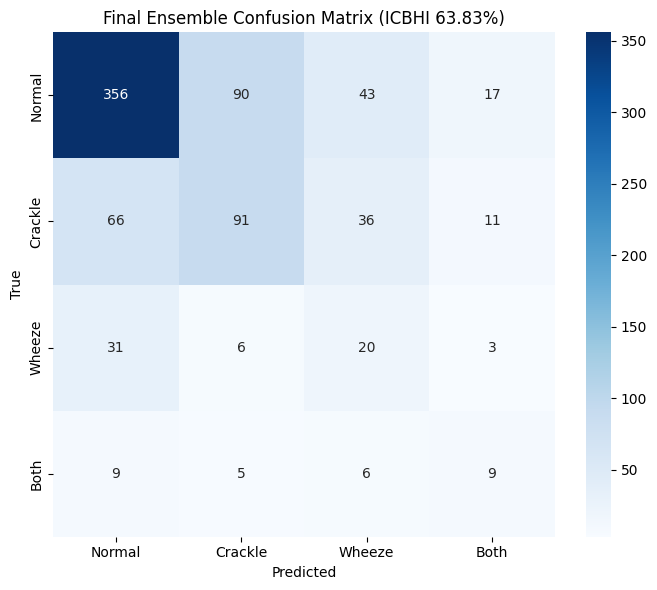

              precision    recall  f1-score   support

      Normal       0.77      0.70      0.74       506
     Crackle       0.47      0.45      0.46       204
      Wheeze       0.19      0.33      0.24        60
        Both       0.23      0.31      0.26        29

    accuracy                           0.60       799
   macro avg       0.41      0.45      0.42       799
weighted avg       0.63      0.60      0.61       799



In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Final ensemble predictions (best constrained model)
y_pred_final = np.argmax(probs_ensemble * best_tw_c, axis=1)
cm_final = confusion_matrix(y_true, y_pred_final, labels=list(range(NUM_SOUND)))

fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(cm_final, annot=True, fmt='d', ax=ax,
            xticklabels=SOUND_NAMES, yticklabels=SOUND_NAMES, cmap='Blues')
ax.set_title(f'Final Ensemble Confusion Matrix (ICBHI {best_score_c*100:.2f}%)')
ax.set_ylabel('True')
ax.set_xlabel('Predicted')
plt.tight_layout()
plt.savefig('/content/drive/MyDrive/pulmoscan semester 7/final_ensemble_confusion_matrix.png', dpi=150)
plt.show()

print(classification_report(y_true, y_pred_final, target_names=SOUND_NAMES, zero_division=0))

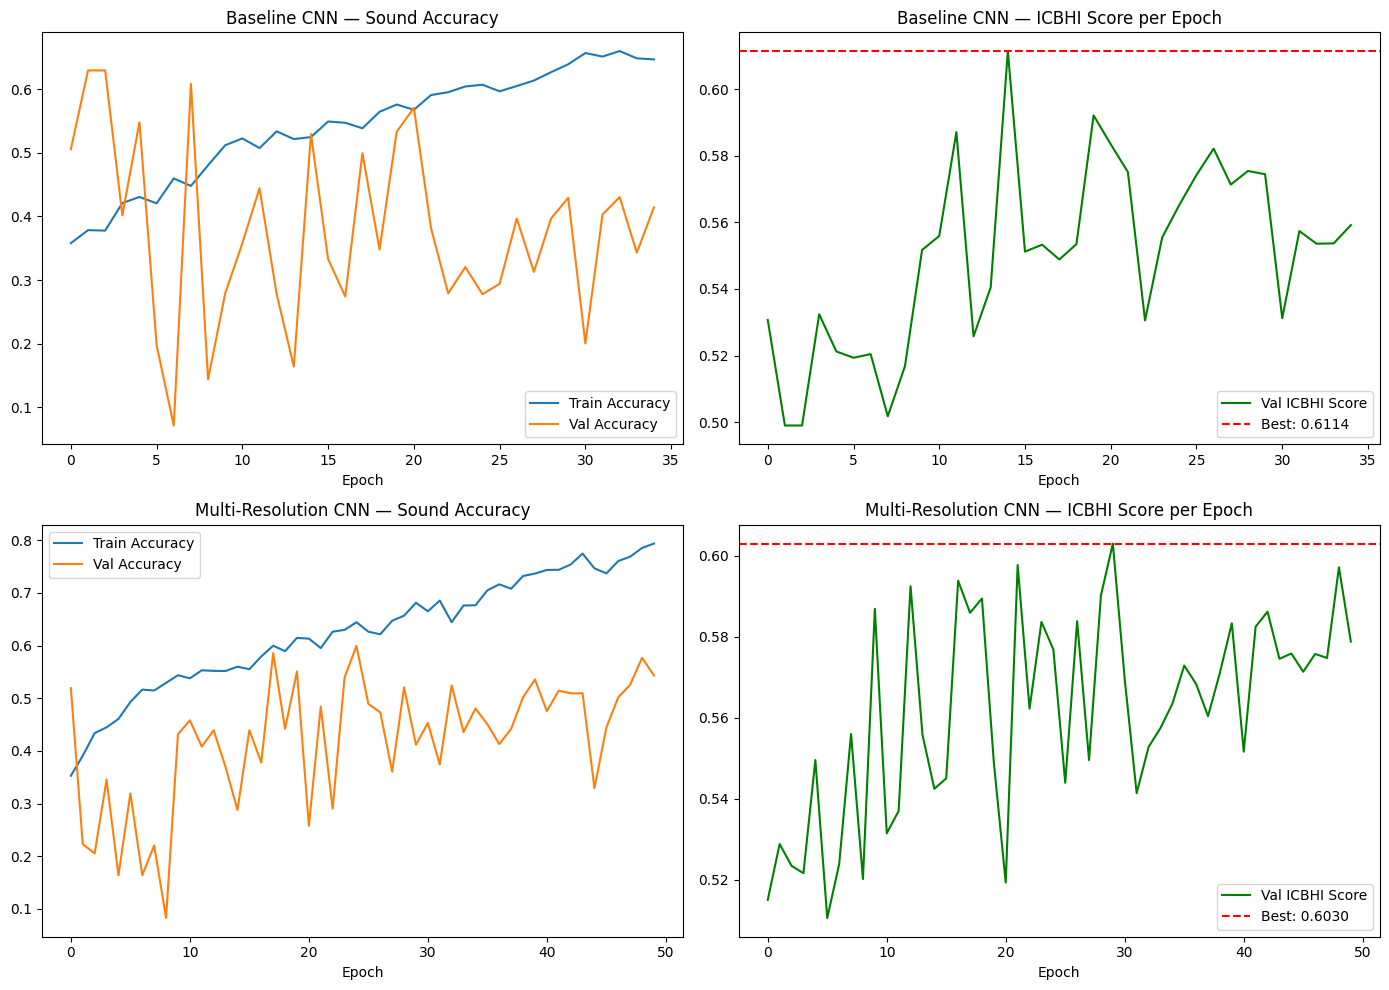

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Baseline retrain (model_B)
axes[0,0].plot(history_B.history['sound_accuracy'], label='Train Accuracy')
axes[0,0].plot(history_B.history['val_sound_accuracy'], label='Val Accuracy')
axes[0,0].set_title('Baseline CNN — Sound Accuracy')
axes[0,0].set_xlabel('Epoch')
axes[0,0].legend()

axes[0,1].plot(history_B.history['val_icbhi'], label='Val ICBHI Score', color='green')
axes[0,1].axhline(y=max(history_B.history['val_icbhi']), color='red', linestyle='--',
                   label=f'Best: {max(history_B.history["val_icbhi"]):.4f}')
axes[0,1].set_title('Baseline CNN — ICBHI Score per Epoch')
axes[0,1].set_xlabel('Epoch')
axes[0,1].legend()

# Multi-resolution CNN (model_A)
axes[1,0].plot(history_A.history['sound_accuracy'], label='Train Accuracy')
axes[1,0].plot(history_A.history['val_sound_accuracy'], label='Val Accuracy')
axes[1,0].set_title('Multi-Resolution CNN — Sound Accuracy')
axes[1,0].set_xlabel('Epoch')
axes[1,0].legend()

axes[1,1].plot(history_A.history['val_icbhi'], label='Val ICBHI Score', color='green')
axes[1,1].axhline(y=max(history_A.history['val_icbhi']), color='red', linestyle='--',
                   label=f'Best: {max(history_A.history["val_icbhi"]):.4f}')
axes[1,1].set_title('Multi-Resolution CNN — ICBHI Score per Epoch')
axes[1,1].set_xlabel('Epoch')
axes[1,1].legend()

plt.tight_layout()
plt.savefig('/content/drive/MyDrive/pulmoscan semester 7/ensemble_component_training_curves.png', dpi=150)
plt.show()

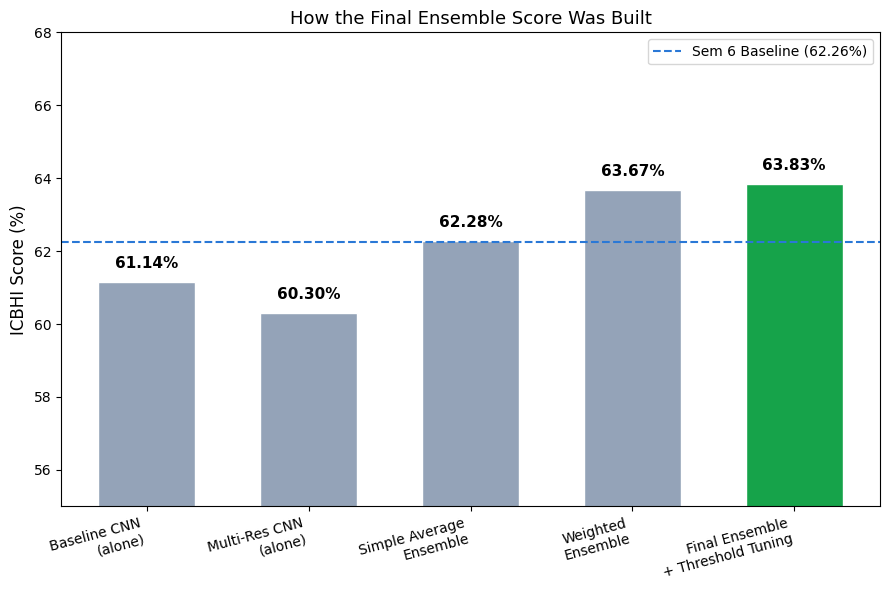

In [ ]:
fig, ax = plt.subplots(figsize=(9, 6))

stages = ['Baseline CNN\n(alone)', 'Multi-Res CNN\n(alone)', 'Simple Average\nEnsemble', 'Weighted\nEnsemble', 'Final Ensemble\n+ Threshold Tuning']
values = [best_icbhi_B*100, best_icbhi_A*100, icbhi_avg*100, best_score*100, best_score_c*100]
colors = ['#94a3b8', '#94a3b8', '#94a3b8', '#94a3b8', '#16a34a']

bars = ax.bar(stages, values, color=colors, edgecolor='white', width=0.6)

ax.axhline(y=62.26, color='#2a78d6', linestyle='--', linewidth=1.5, label='Sem 6 Baseline (62.26%)')

for bar, val in zip(bars, values):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.3,
            f'{val:.2f}%', ha='center', va='bottom', fontsize=11, fontweight='bold')

ax.set_ylabel('ICBHI Score (%)', fontsize=12)
ax.set_title('How the Final Ensemble Score Was Built', fontsize=13)
ax.set_ylim(55, 68)
ax.legend()
plt.xticks(rotation=15, ha='right')
plt.tight_layout()
plt.savefig('/content/drive/MyDrive/pulmoscan semester 7/ensemble_construction_chart.png', dpi=150)
plt.show()